# Problem Set 1: Vector representations, similarity & dimensionality reduction

Analysis of Unstructured Data. Author: Rafał Głodek.

Problems 1–4 are theory answers in Markdown. Problems 5–8 call the code in `src/` and discuss the results. Run the cells from top to bottom: Problem 8 reuses the variables computed in Problem 7.

## Problem 1: Euclidean vs. cosine on the unit sphere

**What we're proving:** when two vectors both have length 1, the squared distance between them depends only on the angle between them.

**Step 1: expand the distance.**

$$\|x - y\|_2^2 = \|x\|_2^2 - 2\langle x, y\rangle + \|y\|_2^2$$

This is just $(a - b)^2 = a^2 - 2ab + b^2$, written with vectors.

**Step 2: use length 1.**

Both lengths are 1, so $\|x\|_2^2 = \|y\|_2^2 = 1$.

Cosine similarity is $\cos\theta = \dfrac{\langle x, y\rangle}{\|x\|_2\,\|y\|_2}$. With lengths of 1 the denominator is 1, so $\cos\theta = \langle x, y\rangle$.

**Step 3: substitute.**

$$\|x - y\|_2^2 = 1 - 2\cos\theta + 1 = 2(1 - \cos\theta) \qquad \blacksquare$$

### Why the neighbour rankings are the same

From the formula, distance $= \sqrt{2(1 - \cos\theta)}$.

As $\cos\theta$ goes up, $1 - \cos\theta$ goes down, so the distance goes down. Higher cosine similarity always means smaller distance, and the relationship never flips (the function is strictly decreasing).

So ranking neighbours by "smallest Euclidean distance" or by "largest cosine similarity" gives exactly the same order and the same $k$ nearest neighbours. Only the scale is different.

| Vectors point... | $\cos\theta$ | Distance |
|---|---|---|
| the same way | 1 | 0 |
| at 90° | 0 | $\sqrt{2}$ |
| opposite ways | −1 | 2 |

## Problem 2: Cosine distance is not a metric

**Definition:** $d_{\cos}(x, y) = 1 - \cos\theta(x, y)$.

A metric needs four things:
1. $d(x, y) \ge 0$
2. $d(x, y) = 0$ only when $x = y$
3. $d(x, y) = d(y, x)$
4. **Triangle inequality:** $d(x, z) \le d(x, y) + d(y, z)$

Cosine distance passes the first three on the unit sphere, but it **fails the triangle inequality**.

### Counterexample in $\mathbb{R}^2$

Take three unit vectors at 0°, 45° and 90°:

$$x = (1, 0), \qquad y = \left(\tfrac{1}{\sqrt{2}}, \tfrac{1}{\sqrt{2}}\right), \qquad z = (0, 1)$$

Compute the cosines (all vectors have length 1, so cosine is just the dot product):

| Pair | Angle | $\cos\theta$ | $d_{\cos} = 1 - \cos\theta$ |
|---|---|---|---|
| $x, y$ | 45° | $\tfrac{\sqrt{2}}{2} \approx 0.707$ | $\approx 0.293$ |
| $y, z$ | 45° | $\tfrac{\sqrt{2}}{2} \approx 0.707$ | $\approx 0.293$ |
| $x, z$ | 90° | $0$ | $1$ |

Check the triangle inequality:

$$d_{\cos}(x, z) = 1 \quad > \quad d_{\cos}(x, y) + d_{\cos}(y, z) \approx 0.586$$

Going "through" $y$ is shorter than going straight from $x$ to $z$, which is impossible for a real distance. So $d_{\cos}$ is **not a metric**. $\blacksquare$

**Why it breaks:** from Problem 1, on the unit sphere $d_{\cos}(x, y) = \tfrac{1}{2}\|x - y\|_2^2$. That's a *squared* Euclidean distance, and squaring breaks the triangle inequality (e.g. on a line, $0 \to 1 \to 2$: $2^2 = 4 > 1^2 + 1^2 = 2$). For small angles, $1 - \cos\theta \approx \theta^2/2$, so small angles get shrunk too much compared to big ones.

### Contrast: angular distance

$$d_{\text{ang}}(x, y) = \frac{\arccos(\cos\theta)}{\pi} = \frac{\theta}{\pi} \in [0, 1]$$

This just measures the angle itself, scaled to $[0, 1]$. Same example:

| Pair | Angle | $d_{\text{ang}}$ |
|---|---|---|
| $x, y$ | 45° | $\tfrac{1}{4}$ |
| $y, z$ | 45° | $\tfrac{1}{4}$ |
| $x, z$ | 90° | $\tfrac{1}{2}$ |

$$d_{\text{ang}}(x, z) = \tfrac{1}{2} \quad \le \quad \tfrac{1}{4} + \tfrac{1}{4} = \tfrac{1}{2} \quad \checkmark$$

The triangle inequality holds (here with equality, since $y$ lies exactly between $x$ and $z$).

**Why angular distance is a metric:** the angle between two points on the unit sphere is the length of the shortest path along the sphere's surface (the great-circle arc). Shortest-path lengths always satisfy the triangle inequality, because a detour through $y$ can never beat the direct path. Dividing by $\pi$ just rescales it.

*Small note:* on vectors that aren't normalised, $x$ and $2x$ have angle 0, so $d_{\text{ang}}$ is only a metric on directions (i.e. on the unit sphere), not on raw vectors.

### Summary

| | $d_{\cos} = 1 - \cos\theta$ | $d_{\text{ang}} = \theta / \pi$ |
|---|---|---|
| Triangle inequality | ✗ fails | ✓ holds |
| Metric? | No | Yes (on the sphere) |
| Neighbour ranking | Same as angle | Same as angle |

Both are increasing functions of $\theta$, so they **rank neighbours the same way**. The difference only matters when you need actual metric properties, e.g. for metric-tree indexes (ball trees, VP-trees) or triangle-inequality pruning, which can give wrong results with $d_{\cos}$.

## Problem 3: Curse of dimensionality

### Part A: in high dimensions, all points are about equally far away

**Setup:** draw $n$ points $X^{(1)}, \dots, X^{(n)}$ uniformly from the cube $[0,1]^d$ and fix a query point $q$. Let $D_{\min}$ and $D_{\max}$ be the distances from $q$ to its nearest and farthest point. We want to show

$$\frac{D_{\max} - D_{\min}}{D_{\min}} \to 0 \quad \text{as } d \to \infty.$$

**Step 1: write the squared distance as a sum.**

For one random point $X$:

$$D^2 = \|X - q\|_2^2 = \sum_{j=1}^{d} \underbrace{(X_j - q_j)^2}_{Z_j}$$

The coordinates $X_j$ are independent, so $D^2$ is a sum of $d$ **independent** terms $Z_j$, each between 0 and 1.

**Step 2: the mean grows like $d$, the spread grows like $\sqrt{d}$.**

- Each $Z_j$ has mean at least $\tfrac{1}{12}$ (the smallest case, when $q_j = \tfrac12$). So the mean is $\mu = \mathbb{E}[D^2] \ge \tfrac{d}{12}$, which grows **linearly** in $d$.
- Each $Z_j$ lies in $[0, 1]$, so $\operatorname{Var}(Z_j) \le \tfrac14$. Independent variances add, so $\operatorname{Var}(D^2) \le \tfrac{d}{4}$, and the standard deviation is at most $\tfrac{\sqrt{d}}{2}$, which grows only like **$\sqrt{d}$**.

So the relative spread is

$$\frac{\text{std}(D^2)}{\mathbb{E}[D^2]} \le \frac{\sqrt{d}/2}{d/12} = \frac{6}{\sqrt{d}} \to 0.$$

The distance gets bigger, but its random wiggle gets **relatively** smaller. This is the law of large numbers.

**Step 3: Chebyshev's inequality.**

For any $\varepsilon > 0$ and one point:

$$P\big(|D^2 - \mu| \ge \varepsilon\mu\big) \le \frac{\operatorname{Var}(D^2)}{\varepsilon^2 \mu^2} \le \frac{d/4}{\varepsilon^2 d^2/144} = \frac{36}{\varepsilon^2 d}.$$

For all $n$ points:

$$P\big(\text{some point has } |D^2 - \mu| \ge \varepsilon\mu\big) \le \frac{36\,n}{\varepsilon^2 d} \to 0 \quad (n \text{ fixed}, \ d \to \infty).$$

So with probability going to 1, **every** squared distance is in $[(1-\varepsilon)\mu,\ (1+\varepsilon)\mu]$. Then

$$\frac{D_{\max}}{D_{\min}} \le \sqrt{\frac{1+\varepsilon}{1-\varepsilon}} \quad\Longrightarrow\quad \frac{D_{\max} - D_{\min}}{D_{\min}} \le \sqrt{\frac{1+\varepsilon}{1-\varepsilon}} - 1.$$

The right side can be made as small as we like by picking a small $\varepsilon$, so $\dfrac{D_{\max} - D_{\min}}{D_{\min}} \to 0$ in probability. $\blacksquare$

**Intuition:** $D$ grows like $\sqrt{d}$, but the gap $D_{\max} - D_{\min}$ stays roughly constant. A constant gap divided by something growing like $\sqrt{d}$ goes to 0, at a rate of about $1/\sqrt{d}$. The nearest and farthest points end up at almost the same distance.

### Part B: almost all of a high-dimensional ball is near its surface

**Step 1: volume scales like $r^d$.**

A $d$-dimensional ball of radius $r$ has volume $V_d(r) = C_d\, r^d$, where $C_d$ is a constant depending only on $d$.

**Step 2: compute the shell fraction.**

The shell of thickness $\varepsilon$ is the unit ball minus the inner ball of radius $1 - \varepsilon$:

$$\frac{V_d(1) - V_d(1-\varepsilon)}{V_d(1)} = \frac{C_d - C_d(1-\varepsilon)^d}{C_d} = 1 - (1-\varepsilon)^d.$$

**Step 3: take the limit.**

Since $0 < 1 - \varepsilon < 1$, raising it to a huge power sends it to 0. More precisely, $(1-\varepsilon)^d \le e^{-\varepsilon d} \to 0$. So

$$1 - (1-\varepsilon)^d \to 1. \qquad \blacksquare$$

**How fast?** Fraction of volume in the outer shell:

| $d$ | $\varepsilon = 0.01$ (outer 1%) | $\varepsilon = 0.1$ (outer 10%) |
|---|---|---|
| 2 | 2.0% | 19% |
| 10 | 9.6% | 65% |
| 100 | 63% | 99.997% |
| 1000 | 99.996% | ≈ 100% |

In 1000 dimensions, a skin only 1% thick holds essentially all the volume. The "inside" of the ball is basically empty.

### Consequences for nearest-neighbour search

- **"Nearest" loses meaning.** By Part A, the nearest point is barely closer than the farthest, so the neighbour ranking is unstable and small noise can change it.
- **Search gets slow.** Exact indexes (k-d trees, ball trees) rely on some points being clearly farther than others to skip them. When all distances are similar, they end up checking every point.
- **Data is spread thin.** By Part B, volume sits near the boundary and grows like $r^d$, so we need exponentially many points in $d$ to have truly close neighbours.

In practice NN search still works because real data has low *intrinsic* dimension, and we help it with dimensionality reduction (e.g. PCA, Problem 4) and approximate NN methods.

## Problem 4: PCA three ways

**Big picture.** PCA looks for the "best" directions to describe the data. "Best" can mean three things:
1. the direction where the data is **most spread out** (maximum variance),
2. the top **eigenvector of the covariance matrix**,
3. the directions that **lose the least information** when we project onto them (minimum reconstruction error).

We show all three give the same answer: the right singular vectors of $X$.

### Setup

- $X \in \mathbb{R}^{n \times p}$: $n$ data points (rows $x_i^\top$), $p$ features. It is **column-centred**: every column has mean 0.
- SVD: $X = U\Sigma V^\top$, where
  - $V = [v_1, \dots, v_p]$ is $p \times p$ orthogonal: its columns are orthonormal **directions in feature space**;
  - $\Sigma$ holds the singular values $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$, which measure **how much the data stretches** along each $v_j$;
  - $U$ is $n \times n$ orthogonal, so $U^\top U = I$.

One identity we use everywhere:

$$X^\top X = V\Sigma^\top U^\top U \Sigma V^\top = V \Sigma^\top\Sigma V^\top = V\,\mathrm{diag}(\sigma_1^2, \dots, \sigma_p^2)\,V^\top$$

(with $\sigma_j = 0$ beyond the rank of $X$).

---

### Part 1: the max-variance direction is $v_1$

**What is $Xw$?** For a unit vector $w$, the $i$-th entry of $Xw$ is $x_i^\top w$, the coordinate of point $i$ along direction $w$. So $Xw$ is the data "squashed" onto the line through $w$.

**Its variance.** The columns of $X$ are centred, so $Xw$ also has mean 0. The variance is then just the average square:

$$\mathrm{Var}(Xw) = \frac{1}{n}\|Xw\|^2 = \frac{1}{n} w^\top X^\top X w.$$

**Rewrite in the $V$ basis.** Let $a = V^\top w$, the coordinates of $w$ in the basis $v_1, \dots, v_p$. Since $V$ is orthogonal, $\|a\| = \|w\| = 1$, i.e. $a_1^2 + \dots + a_p^2 = 1$. Then

$$w^\top X^\top X w = w^\top V\,\mathrm{diag}(\sigma_j^2)\,V^\top w = a^\top \mathrm{diag}(\sigma_j^2)\, a = \sum_{j=1}^{p} \sigma_j^2\, a_j^2.$$

**Maximise.** This is a weighted average of $\sigma_1^2, \dots, \sigma_p^2$ with weights $a_j^2$ that sum to 1. A weighted average can never exceed its largest value, so

$$\sum_j \sigma_j^2 a_j^2 \le \sigma_1^2 \sum_j a_j^2 = \sigma_1^2.$$

Equality holds when all the weight is on $j = 1$: $a = (1, 0, \dots, 0)$, i.e. $w = V a = v_1$. So

$$\boxed{\arg\max_{\|w\|=1} \mathrm{Var}(Xw) = v_1, \qquad \max \mathrm{Var} = \frac{\sigma_1^2}{n}.}$$

(Unique up to sign when $\sigma_1 > \sigma_2$.)

*Intuition:* any other direction is a mix of the $v_j$'s, and mixing in less-stretched directions only dilutes the spread.

---

### Part 2: $v_1$ is the top eigenvector of the covariance $\tfrac{1}{n}X^\top X$

Let $C = \frac{1}{n}X^\top X$ (the sample covariance, since $X$ is centred). From the identity above:

$$C = V\,\mathrm{diag}\!\left(\frac{\sigma_1^2}{n}, \dots, \frac{\sigma_p^2}{n}\right) V^\top.$$

Multiply by $v_1$. Since $V^\top v_1 = e_1$ (the first standard basis vector):

$$C v_1 = V\,\mathrm{diag}\!\left(\frac{\sigma_j^2}{n}\right) e_1 = \frac{\sigma_1^2}{n}\, V e_1 = \frac{\sigma_1^2}{n}\, v_1.$$

So $v_1$ is an eigenvector of $C$ with eigenvalue $\lambda_1 = \sigma_1^2/n$, and it is the **largest** eigenvalue because $\sigma_1$ is the largest singular value. In general:

$$\boxed{C v_j = \lambda_j v_j, \qquad \lambda_j = \frac{\sigma_j^2}{n}.}$$

**Same answer from the eigen side directly (Lagrange multipliers).** Maximise $w^\top C w$ subject to $w^\top w = 1$:

$$\nabla_w\big[w^\top C w - \lambda(w^\top w - 1)\big] = 2Cw - 2\lambda w = 0 \;\Longrightarrow\; Cw = \lambda w.$$

So any optimum is an eigenvector, and its objective value is $w^\top C w = \lambda w^\top w = \lambda$. The best choice is the eigenvector with the **largest** eigenvalue, which is $v_1$ again.

**Useful by-products (used in Problem 6):**
- the variance along $v_j$ is $\lambda_j = \sigma_j^2 / n$;
- the **explained-variance ratio** of component $j$ is $\dfrac{\lambda_j}{\sum_l \lambda_l} = \dfrac{\sigma_j^2}{\sum_l \sigma_l^2}$;
- scikit-learn divides by $n-1$ instead of $n$. That rescales every $\lambda_j$ by the same factor, so the directions and the ratios do not change.

---

### Part 3: the rank-$k$ PCA projection minimises reconstruction error

**What "rank-$k$ projection" means.** Pick $k$ orthonormal directions, stacked as the columns of $W \in \mathbb{R}^{p \times k}$ (so $W^\top W = I_k$). Project each point onto their span:

$$\hat{x}_i = W W^\top x_i.$$

$W^\top x_i$ gives the $k$ coordinates, and $W(\cdot)$ maps them back into $\mathbb{R}^p$. PCA uses $W = V_k = [v_1, \dots, v_k]$. We show this choice minimises

$$E(W) = \sum_{i=1}^{n} \|x_i - \hat{x}_i\|^2.$$

**Step 1: error = total − kept (Pythagoras).** The projection $\hat{x}_i$ and the residual $x_i - \hat{x}_i$ are perpendicular, so

$$\|x_i\|^2 = \|\hat{x}_i\|^2 + \|x_i - \hat{x}_i\|^2, \qquad \|\hat{x}_i\|^2 = \|W W^\top x_i\|^2 = \|W^\top x_i\|^2.$$

Summing over all points:

$$E(W) = \underbrace{\|X\|_F^2}_{\text{fixed}} - \underbrace{\|XW\|_F^2}_{\text{what we keep}}.$$

So **minimising the error is the same as maximising the kept spread** $\|XW\|_F^2 = \sum_{l=1}^k \|X w_l\|^2$, which is $n$ times the total variance along the $k$ directions. This is Part 1 again, with $k$ directions instead of one.

**Step 2: the most we can keep is $\sigma_1^2 + \dots + \sigma_k^2$.** Let $A = V^\top W$ (still $p \times k$ with orthonormal columns). As in Part 1:

$$\|XW\|_F^2 = \sum_{l=1}^k w_l^\top X^\top X w_l = \sum_{j=1}^{p} \sigma_j^2\, h_j, \qquad h_j = \sum_{l=1}^{k} A_{jl}^2 \ \ (\text{squared length of row } j \text{ of } A).$$

The weights $h_j$ have two properties:
- **They sum to $k$:** $\sum_j h_j = \|A\|_F^2 = k$, since $A$ has $k$ orthonormal columns, each of length 1.
- **Each is at most 1:** $h_j = (AA^\top)_{jj}$, and $AA^\top$ is an orthogonal projection $P$, so $h_j = e_j^\top P e_j = \|P e_j\|^2 \le \|e_j\|^2 = 1$.

So we have a total weight of $k$ to spread over $\sigma_1^2 \ge \sigma_2^2 \ge \dots$, with at most 1 per slot. The best we can do is fill the $k$ largest slots:

$$\|XW\|_F^2 \le \sigma_1^2 + \dots + \sigma_k^2.$$

$W = V_k$ achieves this ($h_1 = \dots = h_k = 1$, the rest 0).

**Conclusion.**

$$\boxed{\min_{W^\top W = I_k} \sum_i \|x_i - \hat{x}_i\|^2 = \|X\|_F^2 - \sum_{j=1}^{k} \sigma_j^2 = \sum_{j=k+1}^{p} \sigma_j^2, \quad \text{attained by } W = V_k.}$$

The error left over is exactly the squared singular values we threw away. (This is the Eckart–Young theorem.)

---

### Summary

| Question | Answer |
|---|---|
| Which unit direction has the most variance? | $v_1$, with variance $\sigma_1^2/n$ |
| Top eigenvector of the covariance $\frac{1}{n}X^\top X$? | $v_1$, with eigenvalue $\lambda_1 = \sigma_1^2/n$ |
| Best $k$-dim subspace for reconstruction? | $\mathrm{span}(v_1, \dots, v_k)$, error $= \sum_{j>k} \sigma_j^2$ |

All three come from one fact: $X^\top X = V\,\mathrm{diag}(\sigma_j^2)\,V^\top$. In practice we compute PCA with the **SVD of $X$**. It is numerically more stable than forming $X^\top X$, and it directly gives the directions ($V$), the variances ($\sigma_j^2/n$), and the projected coordinates $XV_k = U_k\Sigma_k$. That is what we implement in Problem 6.

## Problem 5: Three modalities as NumPy arrays

We use one small, real example per modality. Each comes from a library's built-in dataset, so the results are reproducible:

- **Text:** a post from the 20 Newsgroups `sci.space` training set, with headers, footers and quotes removed. We take the first post with 400–1500 characters.
- **Image:** scikit-image's `chelsea`, a standard RGB photo of a cat.
- **Audio:** librosa's `trumpet` example, a short recording copied as an `.ogg` file.

`fetch_samples()` writes the three files into `data/` once. Every array is loaded from those local files. The text becomes its UTF-8 bytes (`uint8`). The image keeps its native `(H, W, 3)` `uint8` layout. The audio is decoded by librosa at its native sampling rate to `float32` in $[-1, 1]$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from src.modalities import (
    decode_text,
    fetch_samples,
    load_audio,
    load_image,
    load_text,
    summary_table,
)
from src.plotting import plot_modalities

paths = fetch_samples()
{name: path.name for name, path in paths.items()}

{'text': 'text_sample.txt',
 'image': 'image_sample.png',
 'audio': 'audio_sample.ogg'}

In [2]:
text_arr = load_text(paths["text"])
image_arr = load_image(paths["image"])
audio_arr, sr = load_audio(paths["audio"])

summary_table({"text": text_arr, "image": image_arr, "audio": audio_arr}, sr)

,shape,ndim,dtype,size,nbytes,min,max,n_chars,sr,duration_s
modality,,,,,,,,,,
text,"(574,)",1,uint8,574,574,10.00000,121.000000,574,<NA>,NaN
image,"(300, 451, 3)",3,uint8,405900,405900,0.00000,231.000000,<NA>,<NA>,NaN
audio,"(117601,)",1,float32,117601,470404,-0.68476,0.631598,<NA>,22050,5.333379


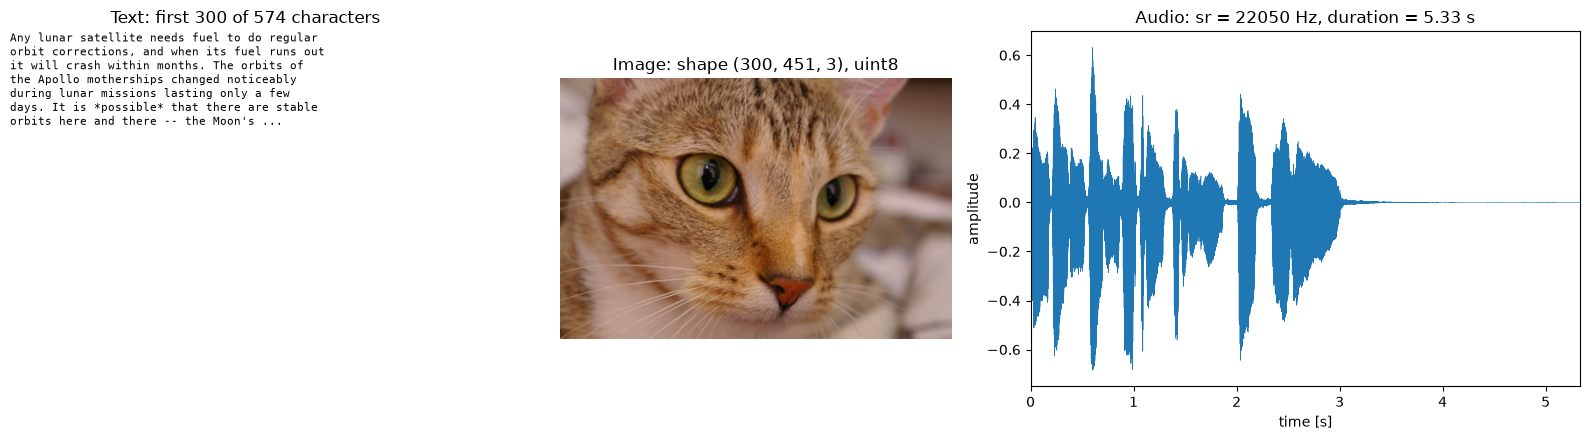

In [3]:
fig = plot_modalities(decode_text(text_arr), image_arr, audio_arr, sr)
plt.show()

### What is a feature vector here?

**Text** 

The array of shape (574,) is a feature vector, where each element corresponds to the numerical encoding of a character (stored as uint8). Alternatively, more meaningful features, such as word frequencies or TF-IDF scores, can be extracted to represent the document's content.

**Image** 

The image can be represented as a 405,900-dimensional feature vector by flattening its $300 \times 451 \times 3$ array, where each value represents the intensity of a red, green, or blue color channel. Such a vector preserves the raw pixel information, while more advanced feature extraction methods can capture other properties such as edges, textures, or shapes.

**Audio** 

The waveform is a 1-D `float32` sequence of shape (117601,), 5.33 s at 22,050 Hz, where each element corresponds to the amplitude of the signal at a particular sampling point. Alternatively, some feature extraction methods (e.g. Fourier transform, statistics, spectral entropy) can provide more information about the sound.

## Problem 6: PCA from scratch via the SVD

**Approach and assumptions:**

- We use the scikit-learn digits: $n = 1797$ images of $8 \times 8$ pixels, flattened to $p = 64$ intensities in 0–16. They are cast to `float64` so that our SVD and sklearn's work at the same precision.
- PCA is the SVD of the centred matrix $X_c = X - \bar{x} = U \Sigma V^\top$ (Problem 4), so we subtract the column means. We do not standardise. All pixels already share the 0–16 scale, so differences in variance are real signal, not units.
- Problem 4 writes $\lambda_j = \sigma_j^2 / n$. We use $\sigma_j^2/(n-1)$ to match sklearn's `explained_variance_`. This scales every eigenvalue by the same constant, so the directions $V$ and the ratios $\mathrm{EVR}_j = \sigma_j^2 / \sum_l \sigma_l^2$ are unchanged.
- Singular vectors are only defined up to sign, because $(u_j, v_j)$ and $(-u_j, -v_j)$ give the same $X_c$. We flip each pair so that the largest magnitude entry of $v_j$ is positive (same way sklearn does it).

In [5]:
import matplotlib.pyplot as plt
import numpy as np

from src.data import load_digits_features
from src.pca import PCA, compare_with_sklearn, n_components_for_variance, theory_checks
from src.plotting import (
    plot_2d_embedding,
    plot_components_as_images,
    plot_cumulative_explained_variance,
)

X, y = load_digits_features()
print(f"X: shape {X.shape}, dtype {X.dtype}")
print(f"y: shape {y.shape}, dtype {y.dtype}, classes {np.unique(y).tolist()}")

X: shape (1797, 64), dtype float64
y: shape (1797,), dtype int64, classes [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [6]:
pca = PCA().fit(X)

comparison = compare_with_sklearn(X)
assert comparison["passes"].all(), comparison[~comparison["passes"]]
comparison

,max_abs_diff,passes
quantity,,
explained_variance_ratio_,1.387779e-16,True
explained_variance_,1.705303e-13,True
singular_values_,2.842171e-13,True
components_[:10],1.831868e-15,True
"transform(X)[:, :10]",1.394440e-13,True
"inverse_transform(transform(X)), k=10",4.618528e-14,True


In [8]:
theory_checks(X)

,check,k,pca_value,theory_value,abs_error,rel_error
0,(a) EVR = sigma^2 / sum sigma^2,<NA>,1.489059e-01,1.489059e-01,5.551115e-17,3.727934e-16
1,(b) eig(cov) = explained_variance_,<NA>,1.790069e+02,1.790069e+02,2.557954e-13,1.428969e-15
2,(c) recon. error = sum_{j>k} sigma_j^2,2,1.543524e+06,1.543524e+06,6.984919e-10,4.525307e-16
3,(c) recon. error = sum_{j>k} sigma_j^2,5,9.824498e+05,9.824498e+05,0.000000e+00,0.000000e+00
4,(c) recon. error = sum_{j>k} sigma_j^2,10,5.651834e+05,5.651834e+05,0.000000e+00,0.000000e+00
5,(c) recon. error = sum_{j>k} sigma_j^2,20,2.282056e+05,2.282056e+05,2.910383e-11,1.275334e-16


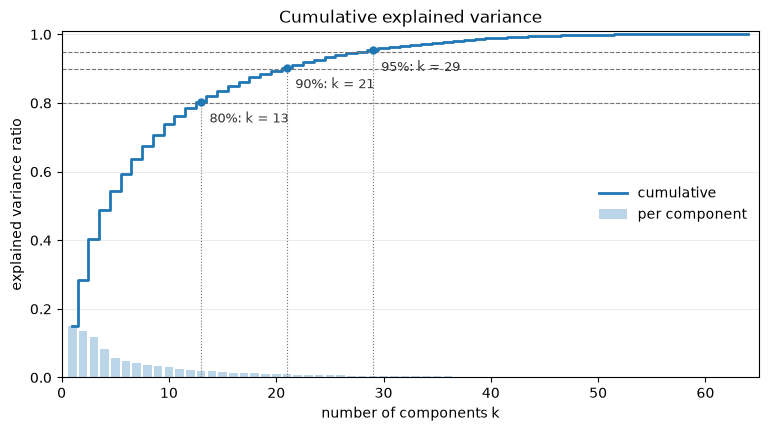

80% of the variance needs k = 13 components
90% of the variance needs k = 21 components
95% of the variance needs k = 29 components


In [7]:
evr = pca.explained_variance_ratio_
fig = plot_cumulative_explained_variance(evr, thresholds=(0.8, 0.9, 0.95))
plt.show()

for t in (0.8, 0.9, 0.95):
    print(f"{t:.0%} of the variance needs k = {n_components_for_variance(evr, t)} components")

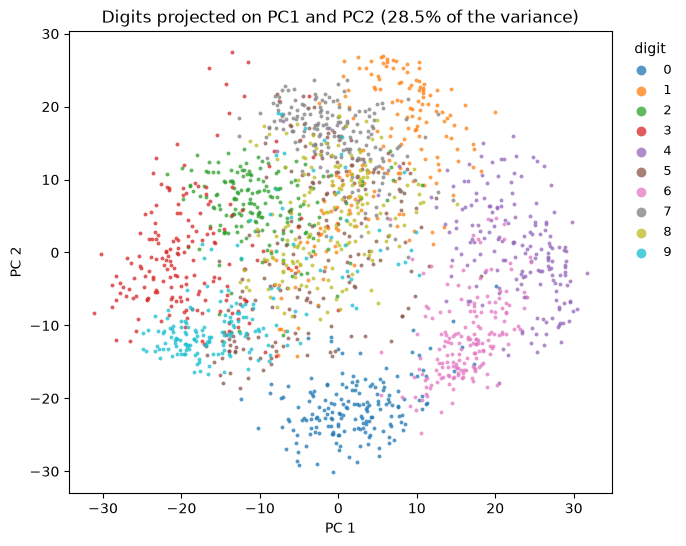

In [8]:
pca_2d = PCA(n_components=2)
Z = pca_2d.fit_transform(X)
share = pca_2d.explained_variance_ratio_.sum()
fig = plot_2d_embedding(
    Z, y,
    title=f"Digits projected on PC1 and PC2 ({share:.1%} of the variance)",
    axis_labels=("PC 1", "PC 2"),
)
plt.show()

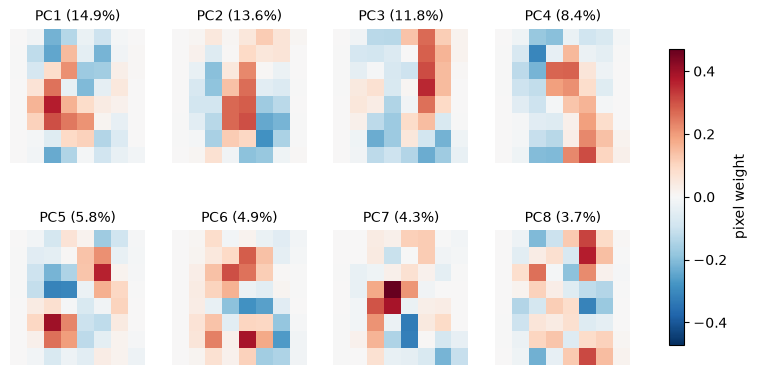

In [9]:
fig = plot_components_as_images(pca.components_, n=8, image_shape=(8, 8), evr=evr)
plt.show()

**Interpretation** 

The first two components keep only 28.5% of the variance (14.9% + 13.6%), and the spectrum decays slowly: 80% needs $k = 13$, 90% needs $k = 21$ and 95% needs $k = 29$ of the 64 dimensions. In the 2-D projection, 0 (bottom), 4 and 6 (right), and 3 and 9 (left) occupy fairly distinct regions, while 1, 2, 5, 7 and 8 pile up and overlap in the centre and top. This is expected. PCA is a linear projection that maximises variance rather than class separation, and two axes throw away more than 70% of the variance, including many of the details that tell these digits apart. Judging from the component images, PC1 rewards the middle-left side of the frame and penalises the top and bottom centre, which pushes 4 and 6 to the right and 3 and 9 to the left. PC2 rewards a vertical stroke down the central columns and penalises the sides of the lower half, which separates the stroke-like 1 and 7 (top) from the ring-shaped 0 (bottom). 

## Problem 7: PCA, t-SNE and UMAP embeddings

**Setup and assumptions**

- We use the same matrix as Problem 6: the raw $1797 \times 64$ digits pixels as `float64`, unscaled, from `load_digits_features()`.
- **PCA:** We use our from-scratch implementation of PCA `PCA(n_components=2)` from Problem 6.
- **t-SNE:** `sklearn.manifold.TSNE` with perplexity 30, `init="pca"`, `learning_rate="auto"`, `max_iter=1000` and `random_state=0`.
- **UMAP:** `umap.UMAP` with `n_neighbors=15`, `min_dist=0.1`, the Euclidean metric and `random_state=0`.

In [9]:
import matplotlib.pyplot as plt

from src.data import load_digits_features
from src.embeddings import compute_embeddings, runtime_table, sensitivity_grid
from src.plotting import plot_embeddings_side_by_side, plot_sensitivity_grid

X, y = load_digits_features()
results = compute_embeddings(X, random_state=0)
runtime_table(results)

,params,runtime_s,extra
method,,,
PCA,n_components=2,0.022,"explained_variance_ratio=[0.149, 0.136]"
t-SNE,"perplexity=30, init=pca, learning_rate=auto, m...",4.728,"kl_divergence=0.7544, n_iter=999"
UMAP,"n_neighbors=15, min_dist=0.1, metric=euclidean...",3.981,


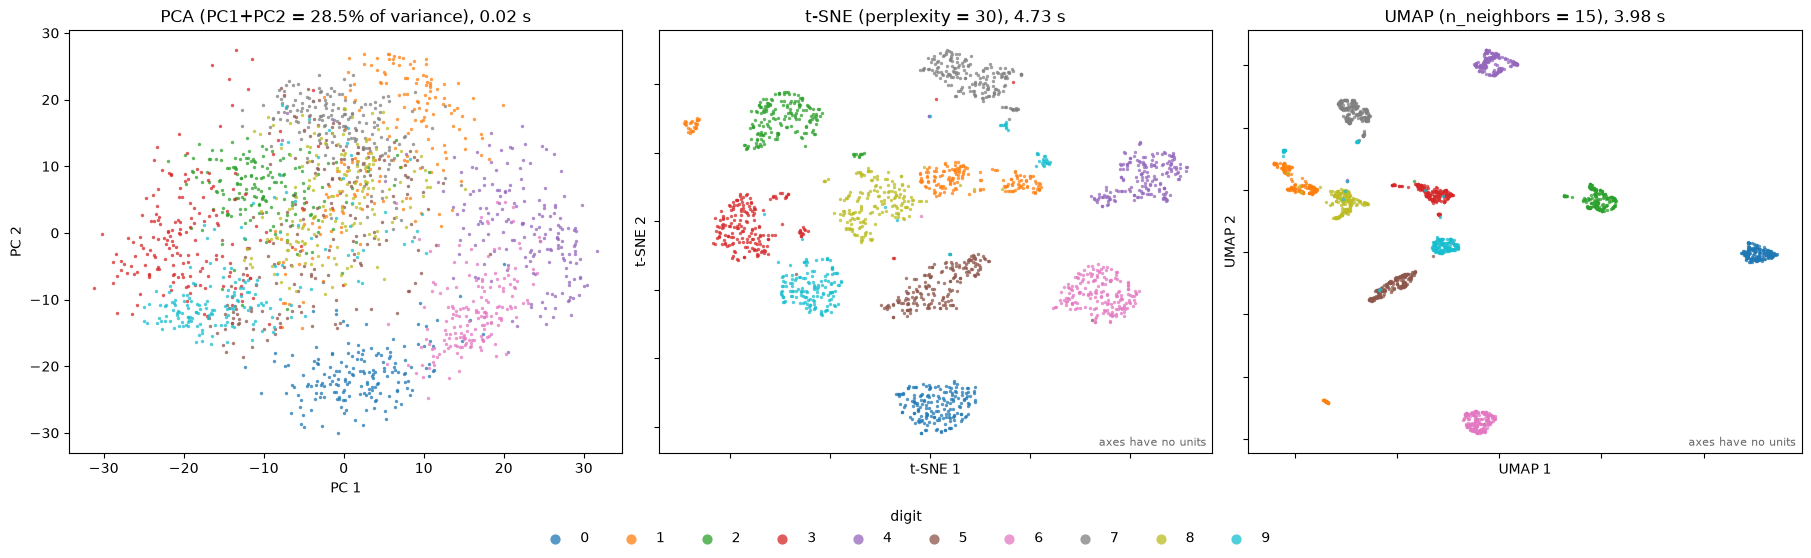

In [10]:
fig = plot_embeddings_side_by_side(results, y)
plt.show()

The next figure is evidence for Problem 8. It re-runs t-SNE with perplexity $\in \{5, 30, 100\}$ and UMAP with `n_neighbors` $\in \{5, 15, 100\}$, keeping everything else fixed.

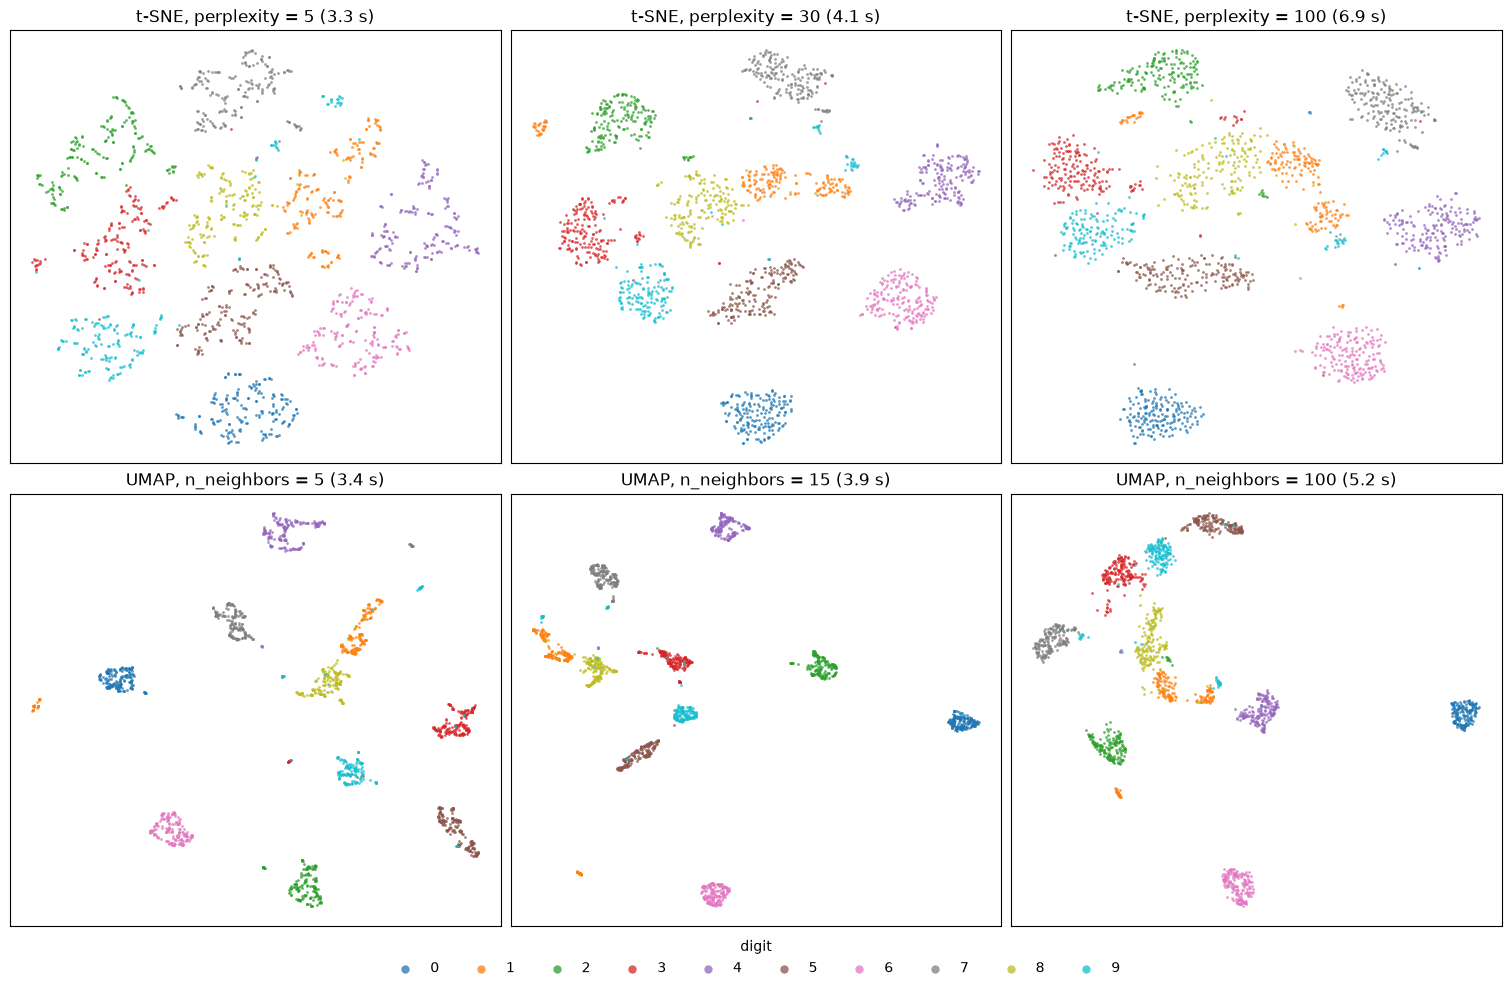

In [12]:
grid = sensitivity_grid(X, random_state=0, perplexities=(5, 30, 100), n_neighbors=(5, 15, 100))
fig = plot_sensitivity_grid(grid, y)
plt.show()

### Observations

PCA leaves the classes heavily mixed: only 0 (bottom), 4/6 (right) and 3/9 (left) form recognisable regions, while 1, 2, 5, 7 and 8 overlap in the centre. t-SNE and UMAP both split the data into ten distinct clusters, and the remaining contacts are the same in both: a group of 1s touches the 8s, the 9s sit right next to the 3s with a few strays near other digits, and digit 1 is broken into several fragments, one of them far from the rest. UMAP packs each class into a much tighter cluster with wide empty gaps between them, while t-SNE's clusters are larger and rounder and fill the plane more evenly. In the t-SNE row, perplexity 5 gives loose clusters spread over the whole canvas, and perplexity 100 gives denser, rounder clusters with bigger gaps, with 0 and 6 pushed further from the rest. In the UMAP row, `n_neighbors = 5` scatters the classes as small separate islands, while `n_neighbors = 100` pulls 1, 3, 5, 7, 8 and 9 into one loose group on the left with 2 just below it, leaving 0, 4 and 6 apart. PCA is by far the fastest (0.008 s), while t-SNE (3.7 s) and UMAP (3.9 s, excluding JIT) take about the same time, and both slow down as their neighbourhood parameter grows (t-SNE 2.8 → 6.7 s, UMAP 3.4 → 5.2 s).

*Why these embeddings differ, and what their distances do and do not mean, is discussed in Problem 8.*

## Problem 8: Comparing the embeddings

**Metrics.** We compare the 2-D embeddings `results` and `grid` from Problem 7 with the raw 64-d digits `X`. Every distance is Euclidean and computed in `float64`, and every metric lies in $[0, 1]$ (1 = perfectly preserved). We use $k = 10$ neighbours unless stated otherwise.

*Local (do near neighbours stay near?)*
- **Trustworthiness** (`sklearn.manifold.trustworthiness`, $k = 10$): penalises *false neighbours*, i.e. points among the $k$ nearest in 2-D that are far away in 64-d.
- **kNN preservation** ($k = 10$): the mean Jaccard overlap between each point's 10-NN set in 64-d and in 2-D, excluding the point itself.
- **kNN accuracy**: 5-fold stratified cross-validated accuracy of a 5-NN classifier trained on the 2-D coordinates (fold seed 0). It measures how well the local class structure survives.

*Global (do large distances keep their meaning?)*
- **Distance correlation**: Spearman $\rho$ between all $\binom{1797}{2} \approx 1.6$M pairwise distances in 64-d and in 2-D.
- **Centroid correlation**: Spearman $\rho$ between the 45 pairwise distances of the 10 class centroids in 64-d and in 2-D. It tests whether the gaps *between* clusters mean anything.

**Seeds.** The embeddings use `random_state=0`, as in Problem 7. For seed stability, t-SNE and UMAP are re-run with seeds 0, 1 and 2, and the centroid correlation is computed *between* the embeddings of two seeds. With the default `init="pca"`, t-SNE ignores the seed, so we also run it with `init="random"`. The relative-contrast check (link to Problem 3) uses 200 query points drawn with seed 0.

In [13]:
from src.plotting import plot_metric_bars, plot_shepard_diagrams
from src.structure_metrics import (
    relative_contrast_table,
    seed_stability,
    sensitivity_table,
    structure_table,
)

# X, y, results and grid come from Problem 7 (same features, seed 0).
structure = structure_table(X, results, y, k=10)
structure

,trustworthiness,knn_preservation,knn_accuracy,distance_corr,centroid_corr
method,,,,,
PCA,0.830003,0.067983,0.633288,0.582371,0.814625
t-SNE,0.992534,0.436318,0.988866,0.510289,0.816074
UMAP,0.988789,0.346339,0.988869,0.369170,0.576416


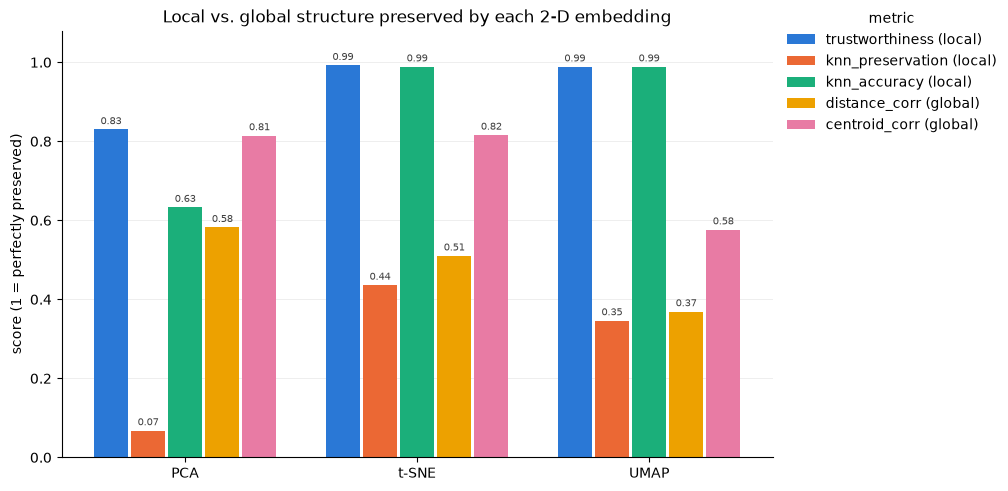

In [14]:
fig = plot_metric_bars(structure)
plt.show()

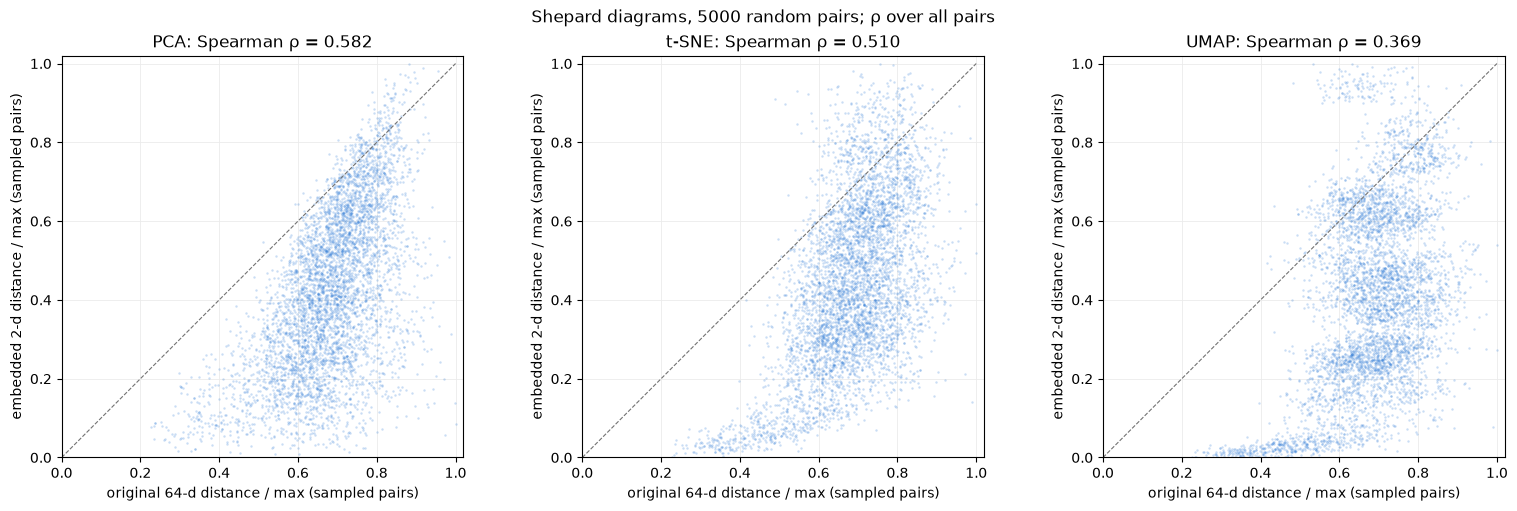

In [15]:
fig = plot_shepard_diagrams(X, results, n_pairs=5000, random_state=0)
plt.show()

In [16]:
sensitivity_table(X, grid, y, k=10)

,method,parameter,value,trustworthiness,knn_preservation,knn_accuracy,distance_corr,centroid_corr
0,t-SNE,perplexity,5.0,0.991053,0.393479,0.988869,0.528213,0.777075
1,t-SNE,perplexity,30.0,0.992534,0.436318,0.988866,0.510289,0.816074
2,t-SNE,perplexity,100.0,0.990538,0.394722,0.982191,0.495988,0.828986
3,UMAP,n_neighbors,5.0,0.988144,0.358165,0.990539,0.388808,0.503426
4,UMAP,n_neighbors,15.0,0.988789,0.346339,0.988869,0.369170,0.576416
5,UMAP,n_neighbors,100.0,0.985642,0.300520,0.986086,0.362387,0.715679


In [17]:
import pandas as pd

pd.concat(
    [
        seed_stability(X, y, seeds=(0, 1, 2), k=10, results=results),
        # With init="pca" t-SNE is seed-independent; random init shows the seed's effect.
        seed_stability(X, y, seeds=(0, 1, 2), k=10, methods=("t-SNE",), tsne_kwargs={"init": "random"}),
    ],
    ignore_index=True,
)

,method,seed_a,seed_b,centroid_corr_between_seeds,trust_seed_a,trust_seed_b
0,PCA,-,-,1.000000,0.830003,0.830003
1,t-SNE,0,1,1.000000,0.992534,0.992534
2,t-SNE,0,2,1.000000,0.992534,0.992534
3,t-SNE,1,2,1.000000,0.992534,0.992534
4,UMAP,0,1,0.785244,0.988789,0.987939
5,UMAP,0,2,0.764954,0.988789,0.988294
6,UMAP,1,2,0.812648,0.987939,0.988294
7,t-SNE (init=random),0,1,0.756390,0.993079,0.992101
8,t-SNE (init=random),0,2,0.855336,0.993079,0.993289
9,t-SNE (init=random),1,2,0.674440,0.992101,0.993289


In [18]:
relative_contrast_table(X, n_queries=200, random_state=0)

,n,d,n_queries,mean,std
point cloud,,,,,
digits (64-d),1797,64,200,3.133015,1.042259
"uniform [0,1]^64",1797,64,200,0.619267,0.066614
"uniform [0,1]^2",1797,2,200,153.502323,259.926025


### Discussion

**Short answer.** PCA preserves global distances best, t-SNE and UMAP preserve local neighbourhoods, and none of the three preserves both. PCA has the highest distance correlation (0.58, against 0.51 for t-SNE and 0.37 for UMAP) but the weakest local scores (trustworthiness 0.83, 10-NN preservation 0.07, kNN accuracy 0.63). In contrast, both t-SNE and UMAP achieve trustworthiness close to 0.99, kNN accuracy 0.99 and five to six times more shared neighbours (0.44 and 0.35), at the cost of a lower distance correlation.

**Global distances: PCA.** PCA projects all observations onto the same two-dimensional linear subspace, defined by the first two principal components. Since this is an orthogonal projection, distances cannot increase, although they may decrease substantially when two observations differ mainly along the discarded directions. Two components keep only 28.5% of the variance (Problem 6), and by Problem 4 the rest, $\sum_{j>2}\sigma_j^2 \approx 1.54 \cdot 10^6$, is simply lost. Pairs that differ mainly in the discarded directions land on top of each other. This produces the overlap of 1, 2, 5, 7 and 8 and the poor local scores.

**Local neighbourhoods: t-SNE and UMAP.** t-SNE and UMAP are designed primarily to preserve relationships between nearby observations. t-SNE represents similarities using probabilities based on distances and adjusts the local scale according to the perplexity parameter, set to 30 in our experiment. UMAP constructs a weighted neighbourhood graph, using n_neighbors=15. Their losses reward keeping neighbours close and say little about anything else. t-SNE is slightly better locally (kNN preservation 0.44 against 0.35). UMAP's `min_dist = 0.1` packs each class into a tight blob, so the order of neighbours inside a cluster is partly lost. Their kNN classification accuracies are almost identical.

**Why t-SNE/UMAP distances cannot be read as similarities.**

1. **Neither method directly optimises the preservation of all pairwise distances** 

t-SNE minimises the Kullback–Leibler divergence between similarity distributions. Pairs with very low original similarity have relatively little direct influence on this objective. The heavy-tailed Student-t distribution also helps separate points in the embedding and reduces the crowding problem. Similarly, UMAP uses attractive relationships between neighbours and repulsive forces involving sampled non-neighbours. As a result, both algorithms can significantly distort distances between observations that are not close neighbours. This behaviour is visible in the Shepard diagrams. Points with similar original distances can have very different distances after dimensionality reduction. In UMAP, the horizontal bands suggest that reduced distances depend strongly on cluster membership rather than on the exact original distances.

2. **Cluster size and density may be misleading** 

Both algorithms use local distance scaling, which can make dense and sparse classes become clusters of similar size. Size and spread on the plot carry no information about the data.

3. **The global layout depends on hyperparameters and seeds**
   - Increasing UMAP's n_neighbors from 5 to 100 raises the centroid-distance correlation from 0.50 to 0.72. Increasing t-SNE's perplexity from 5 to 100 raises it from 0.78 to 0.83. At the same time, trustworthiness remains very high, between 0.986 and 0.993.
   - Across different seeds, the distances between centroids ranges from 0.76 to 0.81 for UMAP and from 0.67 to 0.86 for randomly initialized t-SNE, while trustworthiness remains close to 0.99. This shows that local relationships are much more stable than the global layout.

   If the gaps between clusters measured similarity, they could not depend on the random seed.

4. An additional observation is that t-SNE with PCA initialization achieves nearly the same centroid-distance correlation as PCA itself (0.816 vs 0.815). This is most likely because `init="pca"` gives t-SNE the PCA arrangement of the clusters as its starting point, and the optimisation mainly refines the local structure. With random initialisation, that arrangement is no longer fixed.

Overall, the main purpose of t-SNE and UMAP is to show which observations are close neighbours, not to reproduce the exact distances between them. We can therefore interpret nearby points as having similar local representations, but we should not conclude that two digit classes are more similar simply because their clusters appear closer together.

**Relation to Problems 1–3**
- In Problem 1, we showed that Euclidean and cosine distances on the unit sphere produce the same ordering of nearest neighbours, even though their numerical values differ. This illustrates that neighbourhood structure can be preserved without preserving exact distances. A similar distinction is important when interpreting t-SNE and UMAP embeddings.
- Problem 2 showed that squared Euclidean distance does not generally satisfy the triangle inequality. t-SNE constructs similarity probabilities using squared distances and point-specific scaling parameters. These similarities are not themselves metric distances, so we should not expect Euclidean distances in the embedding to reproduce them exactly.
- Problem 3 demonstrated how distances can become concentrated in high-dimensional spaces. The digits dataset has a relative contrast of 3.13, compared with 0.62 for uniformly distributed data in 64 dimensions. This suggests that the digit images have a more structured, effectively lower-dimensional distribution, allowing nearest-neighbour relationships to remain meaningful.


However, reducing 64 dimensions to only two still introduces substantial distortion. PCA sacrifices information from directions of lower variance, while t-SNE and UMAP focus on preserving local structure, potentially creating artificial gaps between clusters.

**Conclusion**

The experiments demonstrate that dimensionality reduction involves a trade-off between different properties of the original data. PCA is useful when retaining variance and obtaining a consistent linear representation is important, while t-SNE and UMAP are better suited for visualising local neighbourhoods and identifying clusters.

However, the apparent distances, sizes and positions of clusters in t-SNE and UMAP should not be treated as reliable measures of the original similarities. For quantitative comparisons, distances should be calculated in the original feature space or in a suitable higher-dimensional representation, rather than directly from the 2-D visualization.